# Data Overview & Quality — Combined Financial Data IDX

**Mikail Achmad: EDA Laporan Keuangan Emiten IDX (2020–2023)**
*(Untuk Data Analyst Internship at SOKO Financial)*

Dataset ini menggabungkan Balance Sheet (BS), Income Statement (IS), dan Cash Flow (CF) untuk emiten yang tercatat di Bursa Efek Indonesia (IDX), periode 2020–2023.  
Formatnya *long*: satu baris = satu akun, untuk satu emiten, pada satu jenis laporan.

**Tujuan notebook ini**
1. Memahami struktur dan dimensi dataset.
2. Mengecek kualitas data, semisal nilai hilang, duplikasi, kelengkapan baris per emiten.
3. Melihat gambaran skala bisnis (siapa yang terbesar, seberapa lebar rentang nilainya).
4. Menyimpulkan apa yang perlu diwaspadai sebelum lanjut ke analisis berikutnya.

## 1. Setup & Load Data

In [20]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

# Palet warna
BLUE  = "#2a78d6"
AQUA  = "#1baf7a"
RED   = "#d03b3b"
AMBER = "#eda100"
INK   = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#898781"
GRID  = "#e1e0d9"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "text.color": INK,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 11,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
})

def style_ax(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color(GRID)
    ax.spines["bottom"].set_color(GRID)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

def bar_labels(ax, bars, fmt="{:.1f}", pad=0.3, horizontal=False):
    for b in bars:
        if horizontal:
            w = b.get_width()
            ax.text(w + pad, b.get_y() + b.get_height()/2, fmt.format(w),
                    va="center", ha="left", fontsize=9.5, color=INK, fontweight="600")
        else:
            h = b.get_height()
            ax.text(b.get_x() + b.get_width()/2, h + pad, fmt.format(h),
                    va="bottom", ha="center", fontsize=9.5, color=INK, fontweight="600")

In [21]:
# CSV berada satu folder dengan notebook ini di repo
data = "combined_financial_data_idx.csv"

df = pd.read_csv(data)
print(f"Sumber data: {data}")
df.shape

Sumber data: combined_financial_data_idx.csv


(89243, 7)

## 2. Sekilas Struktur Data

In [22]:
df.head(10)

,symbol,account,type,2020,2021,2022,2023
0,AALI,Accounts Payable,BS,7.702640e+11,1.026720e+12,1.224420e+12,8.420640e+11
1,AALI,Accounts Receivable,BS,7.658490e+11,4.581350e+11,8.487700e+11,6.744870e+11
2,AALI,Accumulated Depreciation,BS,-1.092090e+13,-1.213380e+13,-1.330370e+13,-1.443680e+13
3,AALI,Additional Paid In Capital,BS,3.879000e+12,3.879000e+12,3.879000e+12,3.879000e+12
4,AALI,Allowance For Doubtful Accounts Receivable,BS,-2.426100e+10,-2.454300e+10,-2.705700e+10,-2.651600e+10
5,AALI,Basic Average Shares,IS,1.924688e+09,1.924688e+09,1.924688e+09,1.924688e+09
6,AALI,Basic EPS,IS,4.328400e+02,1.024250e+03,8.970800e+02,5.486100e+02
7,AALI,Beginning Cash Position,CF,3.833660e+11,9.788920e+11,3.896020e+12,1.619620e+12
8,AALI,Buildings And Improvements,BS,4.775740e+12,4.858140e+12,4.926100e+12,5.028180e+12
9,AALI,Capital Expenditure,CF,-9.991980e+11,-1.229480e+12,-1.379440e+12,-1.236340e+12


In [23]:
print("Tipe data tiap kolom:")
print(df.dtypes)
print()
print("Penjelasan kolom:")
print("- symbol  : kode saham emiten IDX")
print("- account : nama pos/akun laporan keuangan")
print("- type    : jenis laporan -> BS = Balance Sheet, IS = Income Statement, CF = Cash Flow")
print("- 2020..2023 : nilai akun tsb pada tahun buku terkait (Rupiah)")

Tipe data tiap kolom:
symbol         str
account        str
type           str
2020       float64
2021       float64
2022       float64
2023       float64
dtype: object

Penjelasan kolom:
- symbol  : kode saham emiten IDX
- account : nama pos/akun laporan keuangan
- type    : jenis laporan -> BS = Balance Sheet, IS = Income Statement, CF = Cash Flow
- 2020..2023 : nilai akun tsb pada tahun buku terkait (Rupiah)


## 3. Dimensi Dataset: Ada Berapa Emiten, Akun, dan Jenis Laporan?

In [24]:
type_names = {"BS": "Balance Sheet", "IS": "Income Statement", "CF": "Cash Flow"}
order = ["BS", "IS", "CF"]

n_symbols = df["symbol"].nunique()
n_accounts = df["account"].nunique()
n_rows = len(df)

print(f"Jumlah baris total     : {n_rows:,}")
print(f"Jumlah emiten (symbol) : {n_symbols:,}")
print(f"Jumlah akun unik       : {n_accounts:,}")
print()
print("Jumlah baris per jenis laporan:")
print(df["type"].value_counts().reindex(order).rename(index=type_names))

Jumlah baris total     : 89,243
Jumlah emiten (symbol) : 604
Jumlah akun unik       : 264

Jumlah baris per jenis laporan:
type
Balance Sheet       38675
Income Statement    29487
Cash Flow           21081
Name: count, dtype: int64


C:\Users\Mikail Achmad\AppData\Local\Temp\ipykernel_43240\3297587769.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([type_names[t] for t in order])
C:\Users\Mikail Achmad\AppData\Local\Temp\ipykernel_43240\3297587769.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels([type_names[t] for t in order])


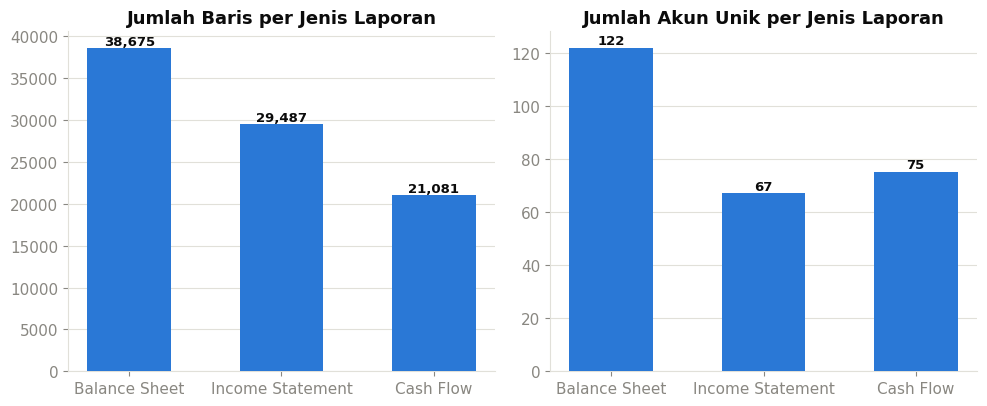

In [25]:
rows_by_type = df["type"].value_counts().reindex(order)
accounts_by_type = df.groupby("type")["account"].nunique().reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))

bars1 = axes[0].bar(order, rows_by_type.values, color=BLUE, zorder=3, width=0.55)
axes[0].set_title("Jumlah Baris per Jenis Laporan")
axes[0].set_xticklabels([type_names[t] for t in order])
style_ax(axes[0])
bar_labels(axes[0], bars1, fmt="{:,.0f}")

bars2 = axes[1].bar(order, accounts_by_type.values, color=BLUE, zorder=3, width=0.55)
axes[1].set_title("Jumlah Akun Unik per Jenis Laporan")
axes[1].set_xticklabels([type_names[t] for t in order])
style_ax(axes[1])
bar_labels(axes[1], bars2, fmt="{:,.0f}")

plt.tight_layout()
plt.show()

## 4. Analisis Data Hilang

In [26]:
years = ["2020", "2021", "2022", "2023"]

missing = pd.DataFrame({
    "jumlah_kosong": df[years].isnull().sum(),
    "persen_kosong": (df[years].isnull().mean() * 100).round(2),
})
missing

,jumlah_kosong,persen_kosong
2020,5255,5.89
2021,4769,5.34
2022,5609,6.29
2023,19412,21.75


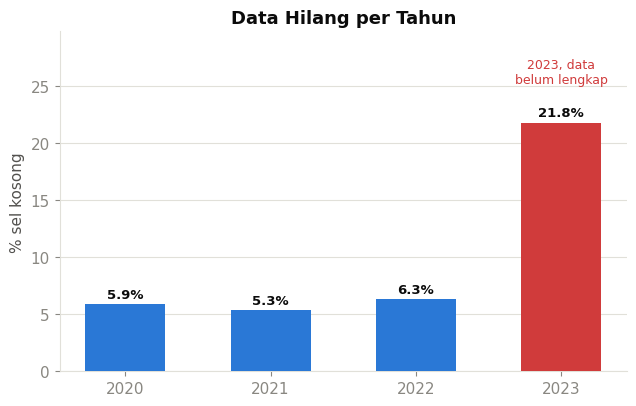

In [39]:
colors = [BLUE, BLUE, BLUE, RED]  # 2023 disorot, karena lebih tinggi dari tahun lain

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(years, missing["persen_kosong"], color=colors, zorder=3, width=0.55)
ax.set_ylabel("% sel kosong")
ax.set_title("Data Hilang per Tahun")
style_ax(ax)
bar_labels(ax, bars, fmt="{:.1f}%")
ax.text(3, missing["persen_kosong"].iloc[-1] + 3.5, "2023, data\nbelum lengkap",
        ha="center", fontsize=9, color=RED)
ax.set_ylim(0, missing["persen_kosong"].max() + 8)
plt.tight_layout()
plt.show()

In [28]:
coverage_2023 = df.groupby("symbol")["2023"].apply(lambda s: s.notna().sum())
n_no_2023 = int((coverage_2023 == 0).sum())
print(f"Emiten tanpa data 2023 sama sekali : {n_no_2023} dari {n_symbols}")
print(f"Artinya sekitar {n_no_2023 / n_symbols:.1%} emiten belum punya laporan 2023 di dataset ini.")

Emiten tanpa data 2023 sama sekali : 68 dari 604
Artinya sekitar 11.3% emiten belum punya laporan 2023 di dataset ini.


> **Catatan:** Data 2020–2022 relatif lengkap (~5–6% kosong. Ini wajar, karena tidak semua akun relevan untuk semua perusahaan, semisal akun khas perbankan pada emiten non-bank).  
> Tapi 2023 melompat ke ~22% kosong, dengan puluhan emiten yang datanya kosong total di tahun itu.

## 5. Cek Duplikasi

In [40]:
dup_count = df.duplicated(subset=["symbol", "account", "type"]).sum()
print(f"Baris duplikat: {dup_count}")

Baris duplikat: 0


## 6. Kelengkapan Baris per Emiten

In [30]:
rows_per_symbol = df.groupby("symbol").size()
rows_per_symbol.describe()

count    604.000000
mean     147.753311
std       18.729826
min       92.000000
25%      139.000000
50%      150.000000
75%      160.000000
max      199.000000
dtype: float64

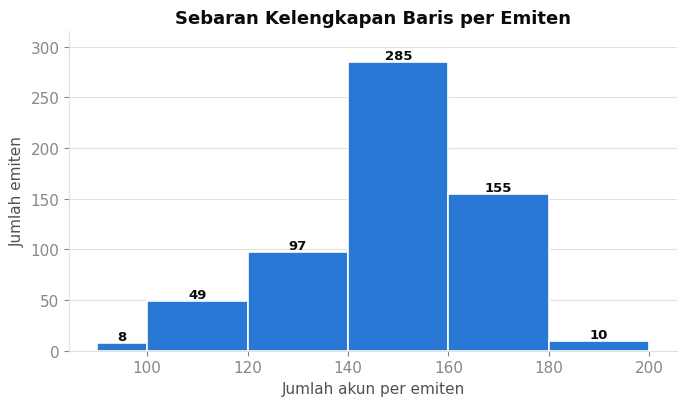

In [41]:
fig, ax = plt.subplots(figsize=(7, 4.2))
bins = [90, 100, 120, 140, 160, 180, 200]
counts, edges, patches = ax.hist(rows_per_symbol, bins=bins, color=BLUE, zorder=3,
                                   edgecolor="white", linewidth=1.2)
ax.set_xlabel("Jumlah akun per emiten")
ax.set_ylabel("Jumlah emiten")
ax.set_title("Sebaran Kelengkapan Baris per Emiten")
style_ax(ax)
for c, l, r in zip(counts, edges[:-1], edges[1:]):
    if c > 0:
        ax.text((l + r) / 2, c + 3, f"{int(c)}", ha="center", fontsize=9.5,
                color=INK, fontweight="600")
ax.set_ylim(0, counts.max() + 30)
plt.tight_layout()
plt.show()

In [32]:
print("10 emiten dengan baris paling sedikit:")
print(rows_per_symbol.sort_values().head(10))
print()
print("10 emiten dengan baris paling banyak:")
print(rows_per_symbol.sort_values(ascending=False).head(10))

10 emiten dengan baris paling sedikit:
symbol
BANK     92
PNBS     94
LCGP     96
BINA     96
BACA     97
MASB     98
BPFI     98
BEKS     98
WOMF    100
BBSI    100
dtype: int64

10 emiten dengan baris paling banyak:
symbol
TLKM    199
JPFA    189
INDY    188
LPKR    184
MAPI    184
WIKA    184
MLPL    181
SSIA    181
ISAT    180
MEDC    180
dtype: int64


## 7. Cakupan Pelaporan Total Revenue per Tahun

In [33]:
revenue = df[df["account"] == "Total Revenue"]
coverage = revenue[years].notna().sum()
coverage

2020    593
2021    596
2022    592
2023    510
dtype: int64

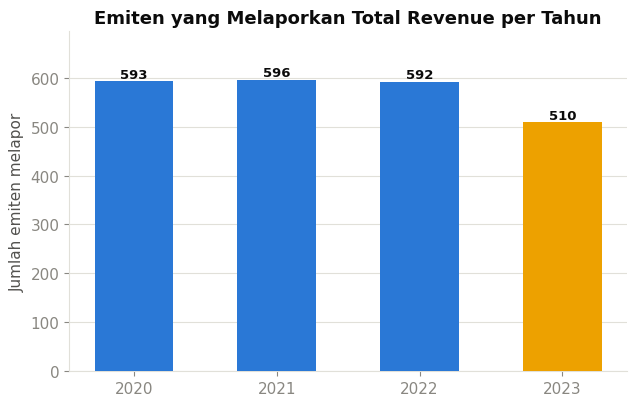

In [42]:
colors2 = [BLUE, BLUE, BLUE, AMBER]

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bars = ax.bar(years, coverage.values, color=colors2, zorder=3, width=0.55)
ax.set_ylabel("Jumlah emiten melapor")
ax.set_title('Emiten yang Melaporkan Total Revenue per Tahun')
ax.set_ylim(0, n_symbols * 1.15)
style_ax(ax)
bar_labels(ax, bars, fmt="{:.0f}")
plt.tight_layout()
plt.show()

## 8. Gambaran Skala Bisnis

In [35]:
revenue[years].describe()

,2020,2021,2022,2023
count,5.930000e+02,5.960000e+02,5.920000e+02,5.100000e+02
mean,4.743255e+12,5.547786e+12,6.366781e+12,7.240096e+12
std,1.493118e+13,1.760771e+13,2.062291e+13,2.305345e+13
min,-1.406037e+10,-8.402781e+10,-3.091413e+09,-1.100300e+13
25%,7.051399e+10,8.119723e+10,1.201930e+11,1.348848e+11
50%,7.280340e+11,8.536270e+11,1.055705e+12,1.151860e+12
75%,3.236310e+12,3.768225e+12,4.443402e+12,4.696578e+12
max,1.750460e+14,2.334850e+14,3.013790e+14,3.165650e+14


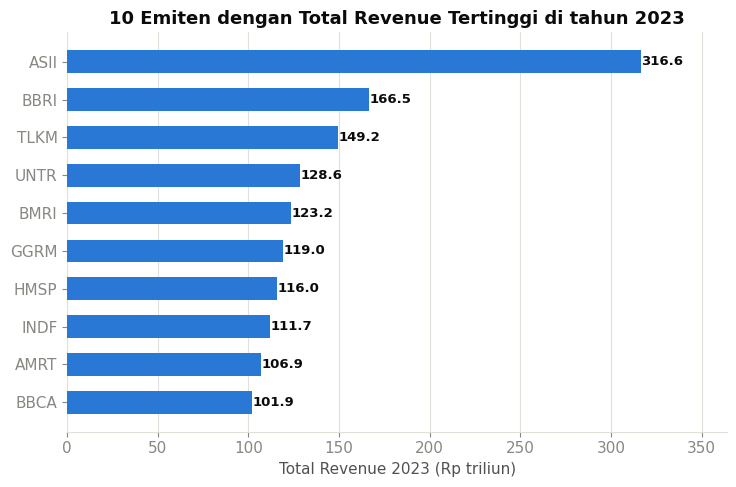

In [43]:
top10 = revenue.nlargest(10, "2023")[["symbol", "2023"]].copy()
top10["revenue_T"] = top10["2023"] / 1e12
top10 = top10.sort_values("revenue_T")

fig, ax = plt.subplots(figsize=(7.5, 5))
bars = ax.barh(top10["symbol"], top10["revenue_T"], color=BLUE, zorder=3, height=0.6)
ax.set_xlabel("Total Revenue 2023 (Rp triliun)")
ax.set_title("10 Emiten dengan Total Revenue Tertinggi di tahun 2023")
style_ax(ax, grid_axis="x")
bar_labels(ax, bars, fmt="{:,.1f}", horizontal=True)
ax.set_xlim(0, top10["revenue_T"].max() * 1.15)
plt.tight_layout()
plt.show()

In [37]:
net_income = df[df["account"] == "Net Income"]
net_income[years].describe()

,2020,2021,2022,2023
count,5.930000e+02,5.960000e+02,5.920000e+02,5.070000e+02
mean,2.858268e+11,5.529420e+11,6.700437e+11,6.950787e+11
std,2.276867e+12,3.049314e+12,4.144318e+12,6.353421e+12
min,-1.673520e+13,-2.139090e+13,-3.957120e+13,-9.039560e+13
25%,-2.663933e+10,-1.448181e+07,9.326684e+06,1.603255e+07
50%,5.441224e+09,2.667946e+10,4.195101e+10,5.268897e+10
75%,1.185220e+11,2.408505e+11,3.221202e+11,3.612095e+11
max,2.713110e+13,3.142270e+13,5.117030e+13,6.009990e+13


> Rentang Net Income sangat lebar (dari puluhan triliun rugi sampai puluhan triliun laba). Ini wajar karena dataset ini mencampur semua skala perusahaan, dari emiten kecil sampai bank BUKU IV dan konglomerasi besar.   
> Perlu hati-hati bila nanti menghitung rata-rata gabungan tanpa memperhatikan perbedaan skala ini.

## 9. Contoh Nama Akun per Jenis Laporan

In [38]:
sample_accounts = pd.DataFrame({
    type_names[t]: pd.Series(sorted(df[df["type"] == t]["account"].unique())[:8])
    for t in order
})
sample_accounts

,Balance Sheet,Income Statement,Cash Flow
0,Accounts Payable,Amortization,Beginning Cash Position
1,Accounts Receivable,Basic Average Shares,Capital Expenditure
2,Accumulated Depreciation,Basic EPS,Capital Expenditure Reported
3,Additional Paid In Capital,Cost Of Revenue,Cash Dividends Paid
4,Allowance For Doubtful Accounts Receivable,Depreciation Amortization Depletion Income Sta...,Cash Flow From Continuing Financing Activities
5,Assets Held For Sale Current,Depreciation And Amortization In Income Statement,Cash Flow From Continuing Investing Activities
6,Available For Sale Securities,Depreciation Income Statement,Cash Flowsfromusedin Operating Activities Direct
7,Buildings And Improvements,Diluted Average Shares,Change In Accrued Expense


## 10. Ringkasan Temuan

- Dataset berisi **89.243 baris**, mencakup **604 emiten IDX**, **264 akun unik**, dan 3 jenis laporan (Balance Sheet, Income Statement, Cash Flow).
- **Tidak ada duplikasi** kombinasi symbol + account + type.
- Data hilang stabil di 2020–2022 (~5–6%), tapi **melonjak jadi ~22% di 2023**. Puluhan emiten tanpa data 2023 sama sekali.
- Jumlah baris per emiten bervariasi 92–199 (median 150) yang mencerminkan perbedaan kelengkapan pos yang dilaporkan tiap perusahaan.
- Skala bisnis dalam dataset sangat lebar dengan emiten besar (ASII, BBRI, TLKM, dst.) mendominasi total revenue, sementara Net Income punya rentang ekstrem dari rugi besar sampai laba besar.

<!-- ## Langkah Selanjutnya

Notebook ini adalah **Minggu 1 dari 3** rencana EDA & Visualisasi:
- **Minggu 2** — Descriptive stats & tren YoY untuk akun kunci (Revenue, Net Income, Total
  Assets, Equity): sebaran nilai, outlier, dan arah tren 2020→2023.
- **Minggu 3** — Rasio keuangan (ROE, ROA, DER, net margin) dari gabungan Balance Sheet +
  Income Statement per emiten per tahun. -->